## 0. 준비

모델에 데이터를 넣기 전에 아래 순서로 준비합니다. 코드는 위에서부터 차례로 실행하고, 각 단계에서 무엇을 하는지는 설명으로 확인합니다.

| 단계 | 하는 일 |
|---|---|
| 0-1 | 도구 불러오기 |
| 0-2 | 데이터 읽기 |
| 0-3 | 데이터 살펴보기 |
| 0-4 | 입력과 정답 나누기 |
| 0-5 | 글자를 숫자로 바꾸기 |
| 0-6 | 훈련용과 평가용 나누기 |
| 0-7 | 빈 값 확인 |
| 0-8 | 빈 값 채우기 |

### 0-1. 도구 불러오기

필요한 도구를 불러옵니다.

- `pandas`: 표 형태의 데이터를 다루는 도구
- `matplotlib`: 그래프를 그리는 도구
- `scikit-learn`: 모델 학습, 데이터 분리를 하는 도구

그래프에 한글이 깨지지 않도록 글꼴도 함께 설정합니다.

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

fonts = {f.name for f in fm.fontManager.ttflist}
plt.rcParams["font.family"] = next((n for n in ["Malgun Gothic", "AppleGothic", "NanumGothic"] if n in fonts), "sans-serif")
plt.rcParams["axes.unicode_minus"] = False

### 0-2. 데이터 읽기

`Titanic-Dataset.csv` 파일을 읽어 `df`라는 표에 저장합니다. 이 표는 원본 그대로이며, 뒤에서 필요한 정보를 꺼내 쓸 때 다시 사용합니다.

표의 행은 승객 한 명, 열은 그 승객의 정보 하나입니다.

In [2]:
path = Path("Titanic-Dataset.csv")
if not path.exists():
    path = Path("3. 분류/Titanic-Dataset.csv")
df = pd.read_csv(path)

print(f"행 {df.shape[0]:,}개 / 열 {df.shape[1]}개")
df.head()

행 891개 / 열 12개


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


### 0-3. 데이터 살펴보기

**데이터의 의미**

- 1912년에 침몰한 타이타닉호의 승객 891명의 기록입니다. (공개 데이터)
- 한 행은 승객 한 명이며, 열은 12개입니다.
- 맞히려는 값은 **생존 여부(`Survived`)** 입니다. 0은 사망, 1은 생존입니다. 값이 두 가지 중 하나이므로 **분류** 문제입니다. (앞의 주택 가격은 숫자를 맞히는 회귀 문제였습니다.)
- 12개 중 **7개 정보**와 생존 여부만 사용합니다. 승객 번호, 이름, 티켓 번호, 객실 번호는 이번 처음 예측에는 사용하지 않고, 뒤의 실험에서 필요할 때 추가합니다.

**이번에 사용하는 7개 정보**

| 항목 | 의미 | 값 |
|---|---|---|
| Sex | 성별 | male(남성), female(여성) |
| Pclass | 객실 등급 | 1, 2, 3 (1등급이 가장 높음) |
| Age | 나이 | 세 |
| SibSp | 함께 탄 형제·자매·배우자 수 | 명 |
| Parch | 함께 탄 부모·자녀 수 | 명 |
| Fare | 승선 요금 | 파운드 |
| Embarked | 탑승 항구 | S(사우샘프턴), C(셰르부르), Q(퀸스타운) |
| **Survived** | **생존 여부 (맞히려는 값)** | **0 사망, 1 생존** |

전체 891명 중 생존 342명 (38.4%), 사망 549명 (61.6%)


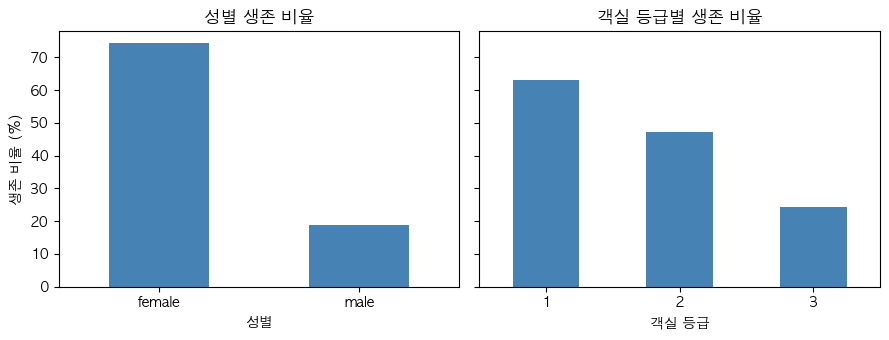

In [3]:
features = ["Sex", "Pclass", "Age", "SibSp", "Parch", "Fare", "Embarked"]

survived = df["Survived"].sum()
print(f"전체 {len(df)}명 중 생존 {survived}명 ({survived / len(df):.1%}), 사망 {len(df) - survived}명 ({1 - survived / len(df):.1%})")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), sharey=True)
df.groupby("Sex")["Survived"].mean().mul(100).plot.bar(ax=axes[0], color="steelblue", rot=0)
df.groupby("Pclass")["Survived"].mean().mul(100).plot.bar(ax=axes[1], color="steelblue", rot=0)
axes[0].set_title("성별 생존 비율"); axes[0].set_xlabel("성별"); axes[0].set_ylabel("생존 비율 (%)")
axes[1].set_title("객실 등급별 생존 비율"); axes[1].set_xlabel("객실 등급")
plt.tight_layout()
plt.show()

여성이 남성보다, 객실 등급이 높을수록 생존 비율이 높습니다. 모델은 이런 정보와 생존의 관계를 학습합니다.

### 0-4. 입력과 정답 나누기

모델은 **정보(입력)와 생존 여부(정답)의 관계**를 배워서, 정답을 모르는 승객의 생존 여부를 예측합니다.

- **입력 `X`:** 생존 여부를 맞히는 데 쓰는 7개 정보
- **정답 `y`:** 생존 여부 (`Survived`)

입력에 생존 여부 자체를 넣으면 정답을 보고 정답을 맞히는 셈이 되므로 넣지 않습니다.

In [4]:
X = df[features].copy()
y = df["Survived"].copy()

print("입력 X:", X.shape, "/ 정답 y:", y.shape)

입력 X: (891, 7) / 정답 y: (891,)


### 0-5. 글자를 숫자로 바꾸기

모델은 숫자만 계산할 수 있습니다. 성별(`male`, `female`)과 탑승 항구(`S`, `C`, `Q`)는 글자이므로 숫자로 바꿉니다.

| 항목 | 바꾸는 방법 |
|---|---|
| Sex | 남성 0, 여성 1 |
| Embarked | S 1, C 2, Q 3 |

탑승 항구는 크기 순서가 있는 값이 아니므로 번호를 붙이는 것은 간단한 처리입니다.

In [5]:
X["Sex"] = X["Sex"].map({"male": 0, "female": 1})
X["Embarked"] = X["Embarked"].map({"S": 1, "C": 2, "Q": 3})

X.head()

,Sex,Pclass,Age,SibSp,Parch,Fare,Embarked
0,0,3,22.0,1,0,7.2500,1.0
1,1,1,38.0,1,0,71.2833,2.0
2,1,3,26.0,0,0,7.9250,1.0
3,1,1,35.0,1,0,53.1000,1.0
4,0,3,35.0,0,0,8.0500,1.0


### 0-6. 훈련용과 평가용 나누기

전체 891명을 **훈련용 80%** 와 **평가용 20%** 로 나눕니다.

| 구분 | 인원 | 용도 |
|---|---|---|
| 훈련용 (`X_train`, `y_train`) | 712명 | 모델이 정보와 생존 여부의 관계를 배우는 데 사용 |
| 평가용 (`X_test`, `y_test`) | 179명 | 학습이 끝난 뒤 예측이 맞는지 확인하는 데 사용 |

**나누는 이유**

- 모델이 학습에 사용한 승객으로 점수를 매기면 모델의 예측 실력이 아니라 학습한 내용을 기억하는 정도를 확인하게 됩니다. 시험 문제를 미리 보고 공부한 뒤 같은 문제로 시험을 보는 것과 같습니다.
- 실제로 필요한 것은 처음 보는 승객의 생존 여부를 맞히는 능력입니다. 그래서 일부를 학습에서 빼 두었다가, 학습 후 이 승객들의 생존 여부를 예측해 실제와 비교합니다.
- 이후의 모든 비교(처음 예측, 정보를 추가한 예측)는 **같은 평가용 승객**으로 합니다. 같은 승객으로 비교해야 결과가 달라진 이유를 정보 추가로 볼 수 있습니다.

**나누는 방식**

- 승객을 무작위로 섞어서 나눕니다.
- `stratify=y`는 생존 비율(약 38%)이 훈련용과 평가용에서 비슷하게 유지되도록 하는 설정입니다. 한쪽에 생존자가 몰리는 것을 막습니다.
- `random_state=42`는 섞는 방식을 고정하는 번호입니다. 모두 같은 승객이 평가용으로 뽑혀서 같은 결과가 나옵니다.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print(f"훈련용 {len(X_train):,}명 / 평가용 {len(X_test):,}명")

훈련용 712명 / 평가용 179명


### 0-7. 빈 값 확인

모델은 값이 비어 있는 정보를 받으면 학습하거나 예측할 수 없습니다. 먼저 어떤 정보에 빈 값이 몇 건 있는지 확인합니다.

In [7]:
missing = X_train.isna().sum()
display(missing[missing > 0].rename("빈 값 수"))

X_train[X_train.isna().any(axis=1)].head()

Age         137
Embarked      2
Name: 빈 값 수, dtype: int64

,Sex,Pclass,Age,SibSp,Parch,Fare,Embarked
692,0,3,NaN,0,0,56.4958,1.0
481,0,2,NaN,0,0,0.0000,1.0
527,0,1,NaN,0,0,221.7792,1.0
557,0,1,NaN,0,0,227.5250,2.0
828,0,3,NaN,0,0,7.7500,3.0


빈 값은 **나이(`Age`)** 에 가장 많습니다. 전체 891명 중 177명(약 20%)의 나이가 기록되어 있지 않습니다. 탑승 항구(`Embarked`)는 전체에서 2명이 비어 있습니다.

### 0-8. 빈 값 채우기

빈 값이 있는 승객을 처리하는 방법은 두 가지입니다.

| 방법 | 특징 |
|---|---|
| 그 승객을 삭제 | 나이가 빈 승객은 전체의 약 20%라서 많은 승객이 사라짐 |
| 빈 값을 채움 | 승객을 유지할 수 있으나 채운 값은 실제 값이 아님 |

이번에는 **빈 값을 채웁니다.**

- **나이:** 중앙값으로 채웁니다. 중앙값은 값을 크기 순으로 세웠을 때 가운데에 있는 값이며, 극단적인 값의 영향을 평균보다 덜 받습니다.
- **탑승 항구:** 가장 많이 나온 값(최빈값)으로 채웁니다. 항구는 숫자의 크기가 의미가 없어서 중앙값을 쓰지 않습니다.
- 두 값 모두 **훈련용 승객에서만** 계산합니다. 평가용은 모델이 처음 보는 승객이어야 하므로, 평가용 정보를 준비 과정에 사용하지 않습니다.
- 계산한 값으로 훈련용과 평가용의 빈 값을 같은 방식으로 채웁니다.
- 채운 값은 실제 값을 알아낸 것이 아닙니다. 나이는 빈 값이 많아서 채운 값이 결과에 영향을 줄 수 있습니다.

In [8]:
fill = {"Age": X_train["Age"].median(), "Embarked": X_train["Embarked"].mode()[0]}   # 훈련용에서 구한 값
X_train = X_train.fillna(fill)
X_test = X_test.fillna(fill)

print(f"채운 값: 나이 {fill['Age']:.0f}세, 탑승 항구 {int(fill['Embarked'])}번(S)")
print("남은 빈 값:", X_train.isna().sum().sum() + X_test.isna().sum().sum(), "건")

채운 값: 나이 28세, 탑승 항구 1번(S)
남은 빈 값: 0 건


빈 값이 모두 채워졌습니다. 아래 셀은 이후 결과를 계산하는 함수입니다. 실행만 하면 됩니다.

- **정확도:** 전체 승객 중 생존 여부를 맞힌 비율
- **생존자 재현율:** 실제 생존자 중 생존으로 맞힌 비율

In [9]:
label = {0: "사망", 1: "생존"}


def evaluate(pred):
    accuracy = (pred == y_test).mean()
    recall = ((pred == 1) & (y_test == 1)).sum() / (y_test == 1).sum()
    return accuracy, recall


def confusion_table(pred):
    actual = y_test.map(label).rename("실제")
    predicted = pd.Series(pred, index=y_test.index).map(label).rename("예측")
    return pd.crosstab(actual, predicted)


print("준비 완료:", len(X_train), "명으로 학습,", len(X_test), "명으로 확인")

준비 완료: 712 명으로 학습, 179 명으로 확인


## 1. 첫 예측

7개 정보로 생존 여부를 예측합니다. 분류 모델 중 **로지스틱 회귀**를 사용하며, 각 승객이 생존할 가능성을 계산해 높으면 생존, 낮으면 사망으로 예측합니다.

비교 기준으로 아무 정보 없이 **모든 승객을 사망으로 예측**했을 때의 정확도도 함께 확인합니다.

In [10]:
model = LogisticRegression(random_state=42, max_iter=1000).fit(X_train, y_train)
pred = model.predict(X_test)

acc_before, recall_before = evaluate(pred)
print(f"모두 사망으로 예측했을 때 정확도: {(y_test == 0).mean():.3f}")
print(f"첫 예측 정확도: {acc_before:.3f}")
print(f"첫 예측 생존자 재현율: {recall_before:.3f}")

모두 사망으로 예측했을 때 정확도: 0.615
첫 예측 정확도: 0.804
첫 예측 생존자 재현율: 0.667


아래 표는 **실제와 예측을 비교한 표**입니다. 세로는 실제, 가로는 예측이며 숫자는 승객 수입니다. 대각선 밖의 두 칸이 틀린 경우입니다.

- 실제 생존 → 예측 사망: 생존자를 놓친 경우
- 실제 사망 → 예측 생존: 사망자를 생존으로 잘못 본 경우

In [11]:
confusion_table(pred)

예측,사망,생존
실제,,
사망,98,12
생존,23,46


예측 결과를 승객별 표로 모읍니다. 이름, 성별, 나이 등은 원본 `df`에서 가져온 것이며, 나이의 빈 값(`NaN`)은 채우기 전 원본 그대로입니다.

In [12]:
result = df.loc[X_test.index, ["Name", "Sex", "Age", "Pclass", "Fare"]].rename(
    columns={"Name": "이름", "Sex": "성별", "Age": "나이", "Pclass": "객실 등급", "Fare": "요금"})
result["실제"] = y_test.map(label)
result["첫 예측"] = pd.Series(pred, index=y_test.index).map(label)
result.head()

,이름,성별,나이,객실 등급,요금,실제,첫 예측
565,"Davies, Mr. Alfred J",male,24.0,3,24.1500,사망,사망
160,"Cribb, Mr. John Hatfield",male,44.0,3,16.1000,사망,사망
553,"Leeni, Mr. Fahim (""Philip Zenni"")",male,22.0,3,7.2250,생존,사망
860,"Hansen, Mr. Claus Peter",male,41.0,3,14.1083,사망,사망
241,"Murphy, Miss. Katherine ""Kate""",female,NaN,3,15.5000,생존,생존


---
# 함께 1회

## ① 틀린 승객 보기

틀린 경우 중 **실제로는 생존했는데 사망으로 예측한 승객**을 모두 확인합니다.

OpenCode 요청 예시

> result 표에서 실제로는 생존했는데 첫 예측이 사망인 승객을 모두 보여줘. 이름, 성별, 나이, 객실 등급, 요금을 같이 보고 싶어.

In [13]:
missed = result[(result["실제"] == "생존") & (result["첫 예측"] == "사망")]
print(f"생존했는데 사망으로 예측한 승객: {len(missed)}명")
missed[["이름", "성별", "나이", "객실 등급", "요금"]]

생존했는데 사망으로 예측한 승객: 23명


,이름,성별,나이,객실 등급,요금
553,"Leeni, Mr. Fahim (""Philip Zenni"")",male,22.0,3,7.2250
559,"de Messemaeker, Mrs. Guillaume Joseph (Emma)",female,36.0,3,17.4000
279,"Abbott, Mrs. Stanton (Rosa Hunt)",female,35.0,3,20.2500
712,"Taylor, Mr. Elmer Zebley",male,48.0,1,52.0000
455,"Jalsevac, Mr. Ivan",male,29.0,3,7.8958
65,"Moubarek, Master. Gerios",male,NaN,3,15.2458
489,"Coutts, Master. Eden Leslie ""Neville""",male,9.0,3,15.9000
869,"Johnson, Master. Harold Theodor",male,4.0,3,11.1333
165,"Goldsmith, Master. Frank John William ""Frankie""",male,9.0,3,20.5250
17,"Williams, Mr. Charles Eugene",male,NaN,2,13.0000


23명 중 **남성이 21명**입니다. 이름을 보면 `Mr.`가 많고 `Master.`가 들어간 승객도 있습니다. 이름에 들어 있는 `Mr.`, `Mrs.`, `Miss.`, `Master.`는 호칭입니다.

- Mr: 성인 남성 / Mrs: 기혼 여성 / Miss: 미혼 여성 / Master: 어린 남자아이

호칭별로 **실제 생존 비율**과 **모델이 생존으로 예측한 비율**을 비교합니다. 평가용에서 호칭별 승객 수가 적을 수 있으므로 승객 수도 함께 봅니다.

OpenCode 요청 예시

> result 표에 원본 df의 Name에서 호칭(Mr, Mrs, Miss, Master, 나머지는 기타)을 뽑아 새 열로 추가해줘. 호칭별로 승객 수, 실제 생존 비율(%), 모델이 생존으로 예측한 비율(%)을 표로 보여줘.

In [14]:
result["호칭"] = df.loc[result.index, "Name"].str.extract(r",\s*([^.]+)\.")[0]
result["호칭"] = result["호칭"].where(result["호칭"].isin(["Mr", "Mrs", "Miss", "Master"]), "기타")

by_title = result.groupby("호칭").agg(
    승객수=("실제", "size"),
    실제_생존비율=("실제", lambda s: (s == "생존").mean() * 100),
    생존_예측비율=("첫 예측", lambda s: (s == "생존").mean() * 100),
).round(0)
by_title

,승객수,실제_생존비율,생존_예측비율
호칭,,,
Master,9,67.0,11.0
Miss,41,68.0,90.0
Mr,105,17.0,4.0
Mrs,18,83.0,78.0
기타,6,33.0,33.0


`Master`(어린 남자아이)는 9명 중 약 67%가 실제로 생존했지만, 모델은 약 11%만 생존으로 예측했습니다. 다른 남성(`Mr`)과 같이 사망으로 예측하고 있습니다.

## ② 이유 추측하기

> **눈에 띈 점:** 생존했는데 사망으로 예측한 승객은 대부분 남성이고, 어린 남자아이(`Master`)는 실제로 많이 생존했지만 모델은 대부분 사망으로 예측한다.
>
> **가설:** 어린 남자아이는 성인 남성과 달리 많이 생존했는데, 지금 모델은 이름의 호칭을 받지 못해서 아이와 성인 남성을 구분하지 못한다.
>
> **해볼 것:** 원본 데이터의 이름(Name)에서 호칭을 뽑아 입력에 추가한다.

## ③ 정보 하나 추가하기

원본 `df`에는 있지만 처음 7개 입력에 넣지 않은 정보가 있습니다. 이름에서 호칭을 뽑아 추가한 뒤 다시 예측합니다.

OpenCode 요청 예시

> 원본 df의 Name에서 호칭(Mr, Mrs, Miss, Master, 나머지는 기타)을 뽑아 입력에 추가해서 같은 로지스틱 회귀로 다시 학습하고 예측값을 pred_a에 저장해줘. X_train과 X_test는 그대로 두고 복사본을 사용해줘.

In [15]:
title = df["Name"].str.extract(r",\s*([^.]+)\.")[0]
title = title.where(title.isin(["Mr", "Mrs", "Miss", "Master"]), "기타")
title_cols = pd.get_dummies(title, prefix="호칭").astype(int)   # 호칭을 모델이 읽을 수 있는 형태로 변환

X_train_a = X_train.join(title_cols)
X_test_a = X_test.join(title_cols)

model_a = LogisticRegression(random_state=42, max_iter=1000).fit(X_train_a, y_train)
pred_a = model_a.predict(X_test_a)

## ④ 결과 확인하기

세 가지를 확인합니다.

1. 정확도와 생존자 재현율이 좋아졌는지
2. 실제와 예측을 비교한 표에서 틀린 칸이 줄었는지
3. 처음 본 23명 중 몇 명이 맞게 바뀌었는지, 새로 틀린 승객은 없는지

In [16]:
acc_a, recall_a = evaluate(pred_a)
print(f"정확도         변경 전: {acc_before:.3f}  →  변경 후: {acc_a:.3f}")
print(f"생존자 재현율  변경 전: {recall_before:.3f}  →  변경 후: {recall_a:.3f}")

print("\n[변경 전]")
display(confusion_table(pred))
print("[변경 후]")
display(confusion_table(pred_a))

정확도         변경 전: 0.804  →  변경 후: 0.832
생존자 재현율  변경 전: 0.667  →  변경 후: 0.739

[변경 전]


예측,사망,생존
실제,,
사망,98,12
생존,23,46


[변경 후]


예측,사망,생존
실제,,
사망,98,12
생존,18,51


In [17]:
result["변경 후 예측"] = pd.Series(pred_a, index=y_test.index).map(label)

check = result.loc[missed.index, ["이름", "호칭", "실제", "첫 예측", "변경 후 예측"]]
display(check)

print(f"처음 본 {len(check)}명 중 변경 후 생존으로 맞힌 승객: {(check['변경 후 예측'] == '생존').sum()}명")
newly_wrong = (result["첫 예측"] == result["실제"]) & (result["변경 후 예측"] != result["실제"])
print(f"변경 전에는 맞았는데 변경 후 틀린 승객: {newly_wrong.sum()}명")

,이름,호칭,실제,첫 예측,변경 후 예측
553,"Leeni, Mr. Fahim (""Philip Zenni"")",Mr,생존,사망,사망
559,"de Messemaeker, Mrs. Guillaume Joseph (Emma)",Mrs,생존,사망,생존
279,"Abbott, Mrs. Stanton (Rosa Hunt)",Mrs,생존,사망,생존
712,"Taylor, Mr. Elmer Zebley",Mr,생존,사망,사망
455,"Jalsevac, Mr. Ivan",Mr,생존,사망,사망
65,"Moubarek, Master. Gerios",Master,생존,사망,사망
489,"Coutts, Master. Eden Leslie ""Neville""",Master,생존,사망,생존
869,"Johnson, Master. Harold Theodor",Master,생존,사망,생존
165,"Goldsmith, Master. Frank John William ""Frankie""",Master,생존,사망,생존
17,"Williams, Mr. Charles Eugene",Mr,생존,사망,사망


처음 본 23명 중 변경 후 생존으로 맞힌 승객: 6명
변경 전에는 맞았는데 변경 후 틀린 승객: 4명


전체 지표가 좋아져도 처음 본 승객이 모두 맞게 바뀌는 것은 아닙니다.

---
# 직접 1회

위의 **첫 예측(`pred`, `result`, `acc_before`, `recall_before`)에서 다시 출발**합니다. 함께 1회에서는 '생존했는데 사망으로 예측한' 승객을 봤고, 이번에는 **사망했는데 생존으로 예측한 승객**을 봅니다. 원본 데이터의 **다른 정보**를 골라 추가합니다.

## ① 틀린 승객 보기

실제로는 사망했는데 생존으로 예측한 승객을 모두 확인합니다. 아래 정보를 함께 붙여 보면 눈에 띄는 점을 찾기 쉽습니다.

| 원본 df의 정보 | 의미 | 참고 |
|---|---|---|
| Age | 나이 | 빈 값이 있던 승객이 있음 (준비 단계에서 중앙값으로 채움) |
| Cabin | 객실 번호 | 기록이 없는 승객이 많음 |
| Ticket | 티켓 번호 | 같은 번호를 쓴 승객은 일행일 수 있음 |

OpenCode 요청 예시

> result 표에서 실제로는 사망했는데 첫 예측이 생존인 승객을 모두 보여줘. 이름, 성별, 나이, 객실 등급, 요금과 함께 원본 df의 Cabin(객실 번호), Ticket(티켓 번호)도 같이 보고 싶어. 나이는 빈 값(NaN)이 그대로 보이게 해줘.

## ② 이유 추측하기

표를 보고 눈에 띄는 점을 하나 골라 아래 문장을 완성합니다.

> 선택한 승객들은 ______ 가 비슷한 것 같다. 이 정보를 추가하면 생존 여부를 더 잘 맞출 것 같다.

예시

- 12명 중 5명은 나이가 비어 있다. 나이가 기록되지 않은 승객이라는 점이 생존과 관련이 있을 수 있는데, 지금 모델은 채워 넣은 나이만 보고 이 사실을 모른다.
- 객실 번호가 기록된 승객과 기록되지 않은 승객은 탑승 위치나 신분이 다를 수 있는데 모델이 이 정보를 모르고 있다.
- 같은 티켓 번호를 쓴 일행이 함께 행동했다면 생존 여부가 비슷할 수 있는데 모델이 이 정보를 모르고 있다.

## ③ 정보 하나 추가하기

고른 정보 **하나만** 추가합니다. 새 예측은 `pred_b`에 저장합니다.

OpenCode 요청 예시 (고른 정보에 맞게 바꿔 요청합니다)

> 원본 df의 Age가 비어 있었던 승객은 1, 아니면 0으로 나타내는 항목을 입력에 추가해서 같은 로지스틱 회귀로 다시 학습하고 예측값을 pred_b에 저장해줘. X_train과 X_test는 그대로 두고 복사본을 사용해줘.

## ④ 결과 확인하기

OpenCode 요청 예시

> 변경 전 pred와 변경 후 pred_b의 정확도와 생존자 재현율을 비교하고, 처음 본 승객들의 변경 전후 예측을 표로 보여줘. 변경 전에는 맞았는데 변경 후 틀린 승객 수도 알려줘.

## 결과 기록

| 항목 | 내용 |
|---|---|
| 본 승객 | 사망했는데 생존으로 예측한 승객 |
| 눈에 띈 점 | |
| 추가한 정보 | |
| 정확도 변경 전 → 후 | |
| 생존자 재현율 변경 전 → 후 | |
| 처음 본 승객의 예측 | |
| 예상과 같았나, 달랐나 | |